In [1]:
import pandas as pd
from pathlib import Path

csv_path = Path("events.csv")

df = pd.read_csv(csv_path)

print("Shape:", df.shape)
print("\nKolom:")
print(df.columns.tolist())

print("\nInformasi data:")
print(df.info())

print("\nContoh data:")
display(df.head())

print("\nJumlah nilai kosong:")
print(df.isna().sum())

# Timestamp diasumsikan dalam milidetik
ts = pd.to_numeric(df["timestamp"], errors="coerce")

print("\nRentang timestamp:")
print("Minimum:", pd.to_datetime(ts.min(), unit="ms"))
print("Maksimum:", pd.to_datetime(ts.max(), unit="ms"))

print("\nDistribusi event:")
print(df["event"].value_counts(dropna=False))

Shape: (2756101, 5)

Kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB
None

Contoh data:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Jumlah nilai kosong:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

Rentang timestamp:
Minimum: 2015-05-03 03:00:04.384000
Maksimum: 2015-09-18 02:59:47.788000

Distribusi event:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


In [2]:
import pandas as pd

# Konversi timestamp ke datetime
df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce"
)

# Kandidat periode
periods = {
    "P1 - Training": ("2015-06-01", "2015-06-30"),
    "P2 - Testing":  ("2015-07-01", "2015-07-14"),
}

for name, (start, end) in periods.items():
    # Batas akhir dibuat inklusif sampai pukul 23:59:59.999...
    mask = (
        (df["datetime"] >= pd.Timestamp(start)) &
        (df["datetime"] < pd.Timestamp(end) + pd.Timedelta(days=1))
    )
    subset = df.loc[mask]

    print(f"\n{'=' * 45}")
    print(name, f"({start} s.d. {end})")
    print("Jumlah interaksi :", len(subset))
    print("Visitor unik     :", subset["visitorid"].nunique())
    print("Item unik        :", subset["itemid"].nunique())
    print("Transaksi        :", subset["transactionid"].nunique())
    print("\nDistribusi event:")
    print(subset["event"].value_counts())



P1 - Training (2015-06-01 s.d. 2015-06-30)
Jumlah interaksi : 610393
Visitor unik     : 313832
Item unik        : 117317
Transaksi        : 4037

Distribusi event:
event
view           590255
addtocart       15095
transaction      5043
Name: count, dtype: int64

P2 - Testing (2015-07-01 s.d. 2015-07-14)
Jumlah interaksi : 309637
Visitor unik     : 171802
Item unik        : 83507
Transaksi        : 1914

Distribusi event:
event
view           299629
addtocart        7535
transaction      2473
Name: count, dtype: int64


count      139.000000
mean     19828.064748
std       4170.654332
min       1528.000000
25%      16831.500000
50%      20621.000000
75%      22461.000000
max      32703.000000
Name: jumlah_interaksi, dtype: float64

10 hari dengan interaksi terbanyak:
date
2015-07-26    32703
2015-07-27    28562
2015-07-25    27106
2015-05-18    27084
2015-07-14    26872
2015-05-19    26799
2015-07-13    26119
2015-07-20    25332
2015-07-08    25035
2015-07-09    24997
Name: jumlah_interaksi, dtype: int64

10 hari dengan interaksi paling sedikit:
date
2015-09-18     1528
2015-09-17    10128
2015-09-16    11495
2015-05-10    12143
2015-06-13    12270
2015-05-09    12695
2015-08-08    12857
2015-08-09    13117
2015-08-15    13423
2015-05-03    13683
Name: jumlah_interaksi, dtype: int64


<Axes: title={'center': 'Jumlah Interaksi per Hari'}, xlabel='Tanggal', ylabel='Jumlah Interaksi'>

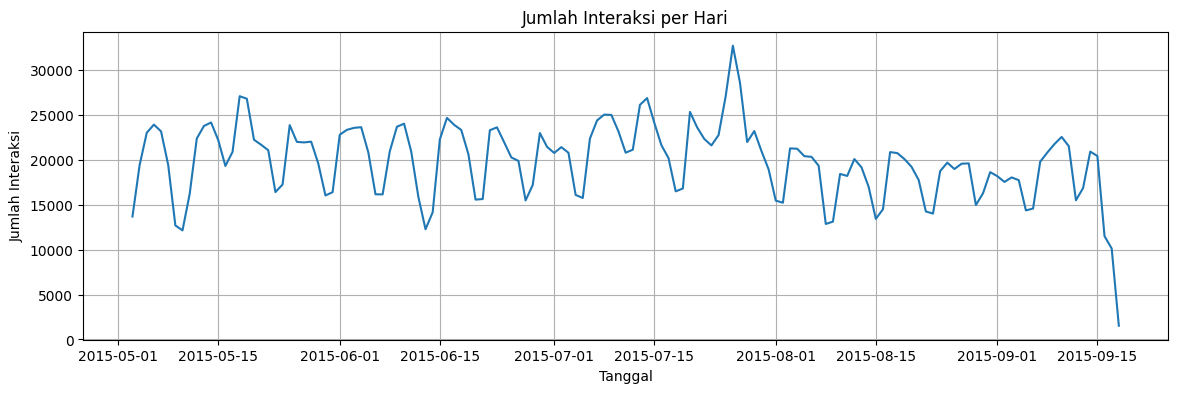

In [3]:
daily_events = (
    df.assign(date=df["datetime"].dt.date)
      .groupby("date")
      .size()
      .rename("jumlah_interaksi")
)

print(daily_events.describe())
print("\n10 hari dengan interaksi terbanyak:")
print(daily_events.nlargest(10))

print("\n10 hari dengan interaksi paling sedikit:")
print(daily_events.nsmallest(10))

daily_events.plot(
    figsize=(14, 4),
    title="Jumlah Interaksi per Hari",
    xlabel="Tanggal",
    ylabel="Jumlah Interaksi",
    grid=True
)


In [4]:
import pandas as pd
from pathlib import Path

# Baca dataset asli
df = pd.read_csv("events.csv")

# Konversi timestamp ke datetime
dt = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce"
)

# Filter P1: 1–30 Juni 2015
mask_p1 = (
    (dt >= "2015-06-01") &
    (dt < "2015-07-01")
)

# Filter P2: 1–14 Juli 2015
mask_p2 = (
    (dt >= "2015-07-01") &
    (dt < "2015-07-15")
)

# Gabungkan hasil filter dan beri label periode
df_p1 = df.loc[mask_p1].copy()
df_p1["fold"] = "P1_training"

df_p2 = df.loc[mask_p2].copy()
df_p2["fold"] = "P2_testing"

df_filtered = pd.concat(
    [df_p1, df_p2],
    ignore_index=True
)

# Simpan satu file CSV
output_path = Path("events_P1-P2.csv")
df_filtered.to_csv(output_path, index=False)

# Verifikasi
print("File:", output_path.resolve())
print("Total baris:", len(df_filtered))
print("\nJumlah baris per fold:")
print(df_filtered["fold"].value_counts())

print("\nRentang tanggal per fold:")
for fold, group in df_filtered.groupby("fold"):
    timestamps = pd.to_datetime(
        group["timestamp"], unit="ms"
    )
    print(
        fold,
        "| Mulai:", timestamps.min(),
        "| Akhir:", timestamps.max()
    )


File: C:\Users\ASUS M3401QC\Documents\UNESA_PYTHON\Semester 7\GrafSainsData\UTS\events_P1-P2.csv
Total baris: 920030

Jumlah baris per fold:
fold
P1_training    610393
P2_testing     309637
Name: count, dtype: int64

Rentang tanggal per fold:
P1_training | Mulai: 2015-06-01 00:00:01.707000 | Akhir: 2015-06-30 23:59:59.292000
P2_testing | Mulai: 2015-07-01 00:00:06.967000 | Akhir: 2015-07-14 23:59:56.104000


In [5]:
import pandas as pd

df = pd.read_csv("events_P1-P2.csv")

ts = pd.to_datetime(df["timestamp"], unit="ms")

print("Jumlah baris:", len(df))
print("Timestamp minimum:", ts.min())
print("Timestamp maksimum:", ts.max())
print("Rentang tanggal:")
print("Mulai:", ts.min().strftime("%d-%m-%Y %H:%M:%S"))
print("Akhir:", ts.max().strftime("%d-%m-%Y %H:%M:%S"))

Jumlah baris: 920030
Timestamp minimum: 2015-06-01 00:00:01.707000
Timestamp maksimum: 2015-07-14 23:59:56.104000
Rentang tanggal:
Mulai: 01-06-2015 00:00:01
Akhir: 14-07-2015 23:59:56


In [6]:
import pandas as pd

df = pd.read_csv("events_P1-P2.csv")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

print("Jumlah baris:", len(df))
print("\nRentang waktu per fold:")

print(
    df.groupby("fold")["datetime"]
      .agg(["count", "min", "max"])
)

Jumlah baris: 920030

Rentang waktu per fold:
              count                     min                     max
fold                                                               
P1_training  610393 2015-06-01 00:00:01.707 2015-06-30 23:59:59.292
P2_testing   309637 2015-07-01 00:00:06.967 2015-07-14 23:59:56.104


In [7]:
import pandas as pd

df = pd.read_csv("events_P1-P2.csv")

# Timestamp asli tetap dipertahankan
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

print(df[["timestamp", "datetime", "fold"]].head())

       timestamp                datetime         fold
0  1433221332117 2015-06-02 05:02:12.117  P1_training
1  1433224214164 2015-06-02 05:50:14.164  P1_training
2  1433221999827 2015-06-02 05:13:19.827  P1_training
3  1433221955914 2015-06-02 05:12:35.914  P1_training
4  1433221337106 2015-06-02 05:02:17.106  P1_training


In [9]:
from pathlib import Path
import pandas as pd

csv_path = Path("events_P1-P2.csv")

df = pd.read_csv(csv_path)

print("Shape:", df.shape)
print("\nJumlah baris per fold:")
print(df["fold"].value_counts())

print("\nDistribusi event per fold:")
print(pd.crosstab(df["fold"], df["event"]))

print("\nJumlah visitor unik:", df["visitorid"].nunique())
print("Jumlah item unik:", df["itemid"].nunique())
print("Jumlah transaction ID unik:", df["transactionid"].nunique())

print("\nNilai kosong:")
print(df.isna().sum())

Shape: (920030, 6)

Jumlah baris per fold:
fold
P1_training    610393
P2_testing     309637
Name: count, dtype: int64

Distribusi event per fold:
event        addtocart  transaction    view
fold                                       
P1_training      15095         5043  590255
P2_testing        7535         2473  299629

Jumlah visitor unik: 475677
Jumlah item unik: 145111
Jumlah transaction ID unik: 5951

Nilai kosong:
timestamp             0
visitorid             0
event                 0
itemid                0
transactionid    912514
fold                  0
dtype: int64
